<a href="https://colab.research.google.com/github/wjd123p/IT326-Project/blob/main/Reports/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Phase 3: Data Mining**




## [1] Problem:

## [2] Data Mining Task:

## [3] Data:

## [4] Data preprocessing:

## [5] Data Mining Technique:

### *5.1 Supervised Learning: Decision Tree Classification*

#### Tools & Libraries Description

For classification, we used the Decision Tree Classifier from `sklearn.tree` to predict students' final grades (`final_grade`). Decision Trees were chosen because they provide interpretable classification rules. Two splitting criteria, Gini Index and Entropy, were applied to compare model performance. The preprocessed dataset was divided into training and testing sets using three ratios: 90/10, 80/20, and 70/30, using `train_test_split` from `sklearn.model_selection`. The models were evaluated using `accuracy_score` from `sklearn.metrics`, while Pandas was used to load and prepare the dataset.



### *5.2 Modeling & Evaluation (Unsupervised Learning: K-Means Clustering)*

#### Tools & Libraries Description

To perform unsupervised clustering and identify natural groupings within the student dataset, the following Python libraries and functions were utilized:
* **`StandardScaler` (from `sklearn.preprocessing`):** Used to standardize numerical features to have a mean of 0 and a variance of 1, ensuring all variables contribute equally to the distance calculations.
* **`KMeans` (from `sklearn.cluster`):** The core algorithm used to partition the dataset into $k$ distinct clusters by minimizing within-cluster variances.
* **`silhouette_score` (from `sklearn.metrics`):** Evaluates cluster cohesion and separation, yielding scores between -1 and 1.
* **`Matplotlib` & `Seaborn`:** Utilized to plot the Elbow curve, Silhouette analysis, and the final cluster scatter plots.
* **`calinski_harabasz_score` (from `sklearn.metrics`):** Measures the ratio of between-cluster to within-cluster variance.
* **`KneeLocator` (from `kneed`):** Detects the elbow point automatically.
* The class label `final_grade` was removed before clustering.

## [6] Evaluation and Comparison:

#### 6.1 Classification - Evaluation and Comparison

### Importing Libraries

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

### Loading the Preprocessed Dataset

In [2]:
df = pd.read_csv("Preprocessed_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (984, 11)


,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,0.514706,0.950739,0.469697,2,1,1,0,0.635071,1.000000,4
1,0,0.852941,1.000000,0.348485,1,1,1,1,0.612954,1.000000,4
2,1,0.647059,0.637931,0.681818,2,1,0,1,0.818325,0.941176,4
3,1,0.308824,0.445813,0.696970,1,1,1,0,0.764613,0.647059,3
4,1,0.250000,0.743842,0.181818,2,1,0,1,0.396524,0.309368,1


### Separating Features and Target

In [3]:
X = df.drop(["final_grade", "final_exam_score"], axis=1)
y = df["final_grade"]

print("Number of features:", X.shape[1])
print("Target attribute:", y.name)

print("\nClass distribution:")
print(y.value_counts().sort_index())

Number of features: 9
Target attribute: final_grade

Class distribution:
final_grade
0      9
1     87
2    258
3    350
4    280
Name: count, dtype: int64


**Description:**

The dataset was divided into input features (X) and the target variable (y), which is `final_grade`. The number of features and the distribution of target classes were displayed to understand the data used for classification.

### Splitting the Dataset (90% Training, 10% Testing)

In [4]:
X_train_90, X_test_90, y_train_90, y_test_90 = train_test_split(
    X, y, test_size=0.10, random_state=42, stratify=y
)

print("Training set size:", X_train_90.shape[0])
print("Testing set size:", X_test_90.shape[0])

Training set size: 885
Testing set size: 99


**Description:**

The dataset was divided into 90% training data and 10% testing data. Stratified splitting was used to help preserve the class distribution in both sets. This partition provides the largest amount of data for training the models.

### Decision Tree Classification Using Gini (90/10)

In [5]:
dt_gini_90 = DecisionTreeClassifier(
    criterion="gini", random_state=42
)

dt_gini_90.fit(X_train_90, y_train_90)

y_pred_gini_90 = dt_gini_90.predict(X_test_90)

accuracy_gini_90 = accuracy_score(y_test_90, y_pred_gini_90)

print("Gini Accuracy:", accuracy_gini_90)
print("Gini Accuracy (%):", accuracy_gini_90 * 100)

Gini Accuracy: 0.43434343434343436
Gini Accuracy (%): 43.43434343434344


**Description:**

A Decision Tree classifier using the Gini Index was trained on 90% of the dataset and evaluated on the remaining 10%. The model achieved an accuracy of 43.43% on the testing set, providing a baseline for comparison with the Entropy-based model.

**Confusion Matrix – Gini (90/10)**




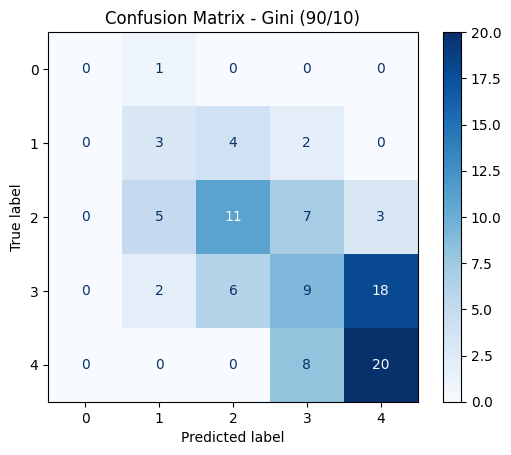

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test_90,
    y_pred_gini_90,
    values_format="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Gini (90/10)")
plt.show()

**Description**
The confusion matrix shows the performance of the Gini-based Decision Tree using a 90/10 train-test split. The model correctly classified some instances across the five classes, with better predictions for class 4. Misclassifications occurred mainly between neighboring classes.

### Decision Tree Classification Using Entropy (90/10)

In [8]:
dt_entropy_90 = DecisionTreeClassifier(
    criterion="entropy", random_state=42
)

dt_entropy_90.fit(X_train_90, y_train_90)

y_pred_entropy_90 = dt_entropy_90.predict(X_test_90)

accuracy_entropy_90 = accuracy_score(
    y_test_90, y_pred_entropy_90
)

print("Entropy Accuracy:", accuracy_entropy_90)
print("Entropy Accuracy (%):", accuracy_entropy_90 * 100)

Entropy Accuracy: 0.4444444444444444
Entropy Accuracy (%): 44.44444444444444


**Description:**

A Decision Tree classifier using Entropy was trained on 90% of the dataset and evaluated on the remaining 10%. The model achieved an accuracy of 44.44%, slightly outperforming the Gini-based model under this partition.

**Confusion Matrix – Entropy (90/10)**

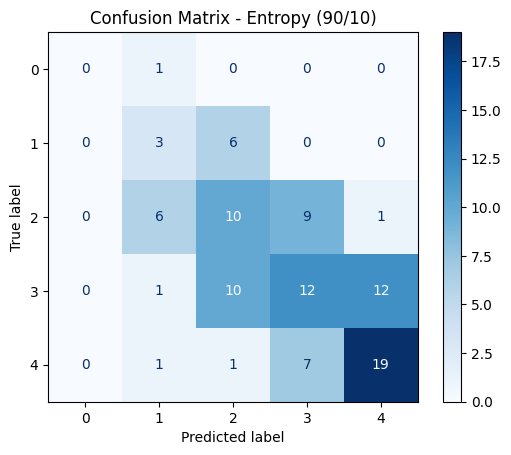

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test_90,
    y_pred_entropy_90,
    values_format="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Entropy (90/10)")
plt.show()

**Description**

The confusion matrix shows the performance of the Entropy-based Decision Tree using a 90/10 train-test split. The matrix illustrates the correctly and incorrectly classified instances across the five classes. The results can be compared with the Gini model to evaluate classification performance.

### Splitting the Dataset (80% Training, 20% Testing)

In [12]:
X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training set size:", X_train_80.shape[0])
print("Testing set size:", X_test_80.shape[0])

Training set size: 787
Testing set size: 197


**Description:**

The dataset was divided into 80% training data and 20% testing data. Stratified splitting was used to help preserve the class distribution in both sets. Compared with the 90/10 partition, this setup provides a larger testing set for evaluating model performance.

### Decision Tree Classification Using Gini (80/20)

In [13]:
dt_gini_80 = DecisionTreeClassifier(
    criterion="gini", random_state=42
)

dt_gini_80.fit(X_train_80, y_train_80)

y_pred_gini_80 = dt_gini_80.predict(X_test_80)

accuracy_gini_80 = accuracy_score(y_test_80, y_pred_gini_80)

print("Gini Accuracy:", accuracy_gini_80)
print("Gini Accuracy (%):", accuracy_gini_80 * 100)

Gini Accuracy: 0.4213197969543147
Gini Accuracy (%): 42.13197969543147


**Description:**

A Decision Tree classifier using the Gini Index was trained on 80% of the dataset and evaluated on the remaining 20%. The model achieved an accuracy of 42.13%, which was slightly lower than its accuracy with the 90/10 partition.

**Confusion Matrix – Gini (80/20)**

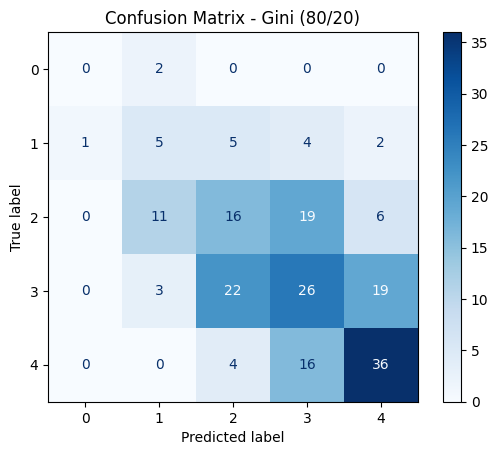

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test_80,
    y_pred_gini_80,
    values_format="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Gini (80/20)")
plt.show()

**Description:**

The confusion matrix shows the performance of the Gini-based Decision Tree using an 80/20 train-test split. The diagonal cells represent correctly classified instances, while the other cells represent misclassifications. The results help evaluate the model's classification performance across the five classes.

### Decision Tree Classification Using Entropy (80/20)

In [15]:
dt_entropy_80 = DecisionTreeClassifier(
    criterion="entropy", random_state=42
)

dt_entropy_80.fit(X_train_80, y_train_80)

y_pred_entropy_80 = dt_entropy_80.predict(X_test_80)

accuracy_entropy_80 = accuracy_score(
    y_test_80, y_pred_entropy_80
)

print("Entropy Accuracy:", accuracy_entropy_80)
print("Entropy Accuracy (%):", accuracy_entropy_80 * 100)

Entropy Accuracy: 0.43147208121827413
Entropy Accuracy (%): 43.14720812182741


**Description:**

A Decision Tree classifier using Entropy was trained on 80% of the dataset and evaluated on the remaining 20%. The model achieved an accuracy of 43.15%, slightly outperforming the Gini-based model under this partition.

**Confusion Matrix – Entropy (80/20)**

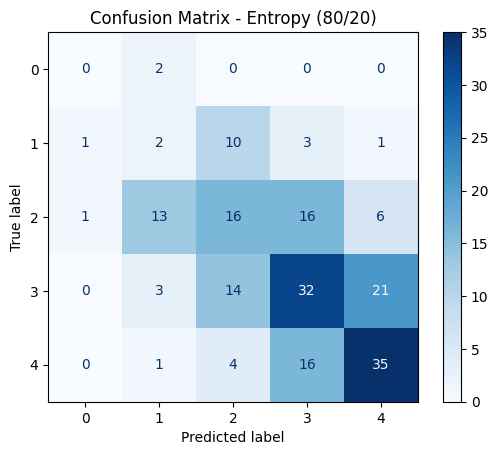

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test_80,
    y_pred_entropy_80,
    values_format="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Entropy (80/20)")
plt.show()

**Description:**

The confusion matrix illustrates the performance of the Entropy-based Decision Tree using an 80/20 train-test split. Correct predictions appear along the main diagonal, while values outside the diagonal indicate misclassified instances. This matrix can be compared with the Gini model to identify differences in classification performance.

### Splitting the Dataset (70% Training, 30% Testing)

In [17]:
X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print("Training set size:", X_train_70.shape[0])
print("Testing set size:", X_test_70.shape[0])

Training set size: 688
Testing set size: 296


**Description:**

The dataset was divided into 70% training data and 30% testing data. Stratified splitting was used to help preserve the class distribution in both sets. This partition provides the largest testing set among the three experiments.

### Decision Tree Classification Using Gini (70/30)

In [18]:
dt_gini_70 = DecisionTreeClassifier(
    criterion="gini", random_state=42
)

dt_gini_70.fit(X_train_70, y_train_70)

y_pred_gini_70 = dt_gini_70.predict(X_test_70)

accuracy_gini_70 = accuracy_score(y_test_70, y_pred_gini_70)

print("Gini Accuracy:", accuracy_gini_70)
print("Gini Accuracy (%):", accuracy_gini_70 * 100)

Gini Accuracy: 0.39864864864864863
Gini Accuracy (%): 39.86486486486486


**Description:**

A Decision Tree classifier using the Gini Index was trained on 70% of the dataset and evaluated on the remaining 30%. The model achieved an accuracy of 39.86%, its lowest accuracy among the three partitions.

**Confusion Matrix – Gini (70/30)**

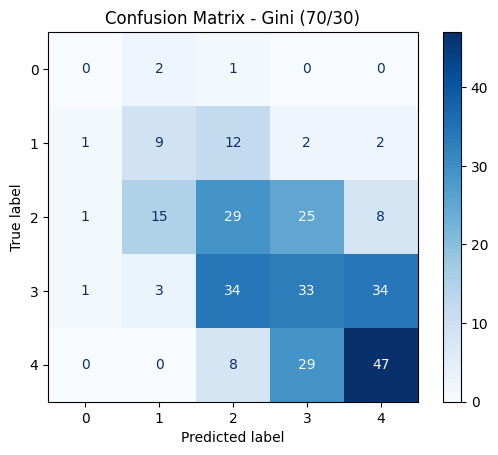

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test_70,
    y_pred_gini_70,
    values_format="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Gini (70/30)")
plt.show()

**Description:**

The confusion matrix evaluates the Gini-based Decision Tree using a 70/30 train-test split. It shows the number of correct and incorrect predictions for each class. The larger test set provides more instances for evaluating the model's classification performance.

### Decision Tree Classification Using Entropy (70/30)

In [20]:
dt_entropy_70 = DecisionTreeClassifier(
    criterion="entropy", random_state=42
)

dt_entropy_70.fit(X_train_70, y_train_70)

y_pred_entropy_70 = dt_entropy_70.predict(X_test_70)

accuracy_entropy_70 = accuracy_score(
    y_test_70, y_pred_entropy_70
)

print("Entropy Accuracy:", accuracy_entropy_70)
print("Entropy Accuracy (%):", accuracy_entropy_70 * 100)

Entropy Accuracy: 0.4594594594594595
Entropy Accuracy (%): 45.94594594594595


**Description:**

A Decision Tree classifier using Entropy was trained on 70% of the dataset and evaluated on the remaining 30%. The model achieved an accuracy of 45.95%, its highest accuracy among the three partitions and higher than the Gini-based model under the same partition.

**Confusion Matrix – Entropy (70/30)**

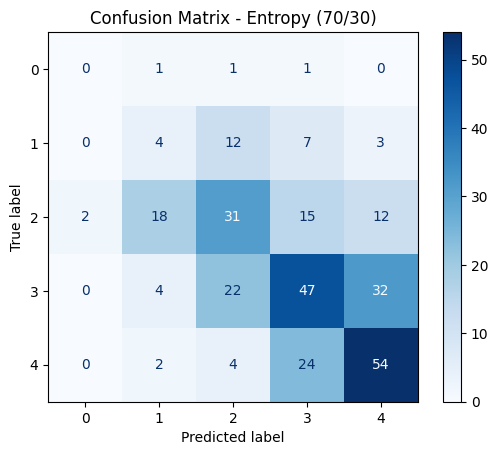

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test_70,
    y_pred_entropy_70,
    values_format="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Entropy (70/30)")
plt.show()

**Description:**

The confusion matrix shows the performance of the Entropy-based Decision Tree using a 70/30 train-test split. The diagonal cells represent correct predictions, while the remaining cells show classification errors. These results help assess the model and compare it with the Gini-based Decision Tree under the same partition.

### Comparing Classification Accuracy

In [22]:
accuracy_results = pd.DataFrame({
    "Partition": ["90/10", "80/20", "70/30"],
    "Gini Accuracy (%)": [
        accuracy_gini_90 * 100,
        accuracy_gini_80 * 100,
        accuracy_gini_70 * 100
    ],
    "Entropy Accuracy (%)": [
        accuracy_entropy_90 * 100,
        accuracy_entropy_80 * 100,
        accuracy_entropy_70 * 100
    ]
})

display(accuracy_results.round(2))

,Partition,Gini Accuracy (%),Entropy Accuracy (%)
0,90/10,43.43,44.44
1,80/20,42.13,43.15
2,70/30,39.86,45.95


**Description:**

The comparison table summarizes the accuracy of the Gini and Entropy Decision Tree classifiers across the three partitions. Entropy achieved higher accuracy than Gini in all three partitions.

**Conclusion:**

The highest accuracy was achieved by Entropy with the 70/30 partition at 45.95%, while the lowest accuracy was achieved by Gini with the 70/30 partition at 39.86%.

**Final Decision Tree Visualization**

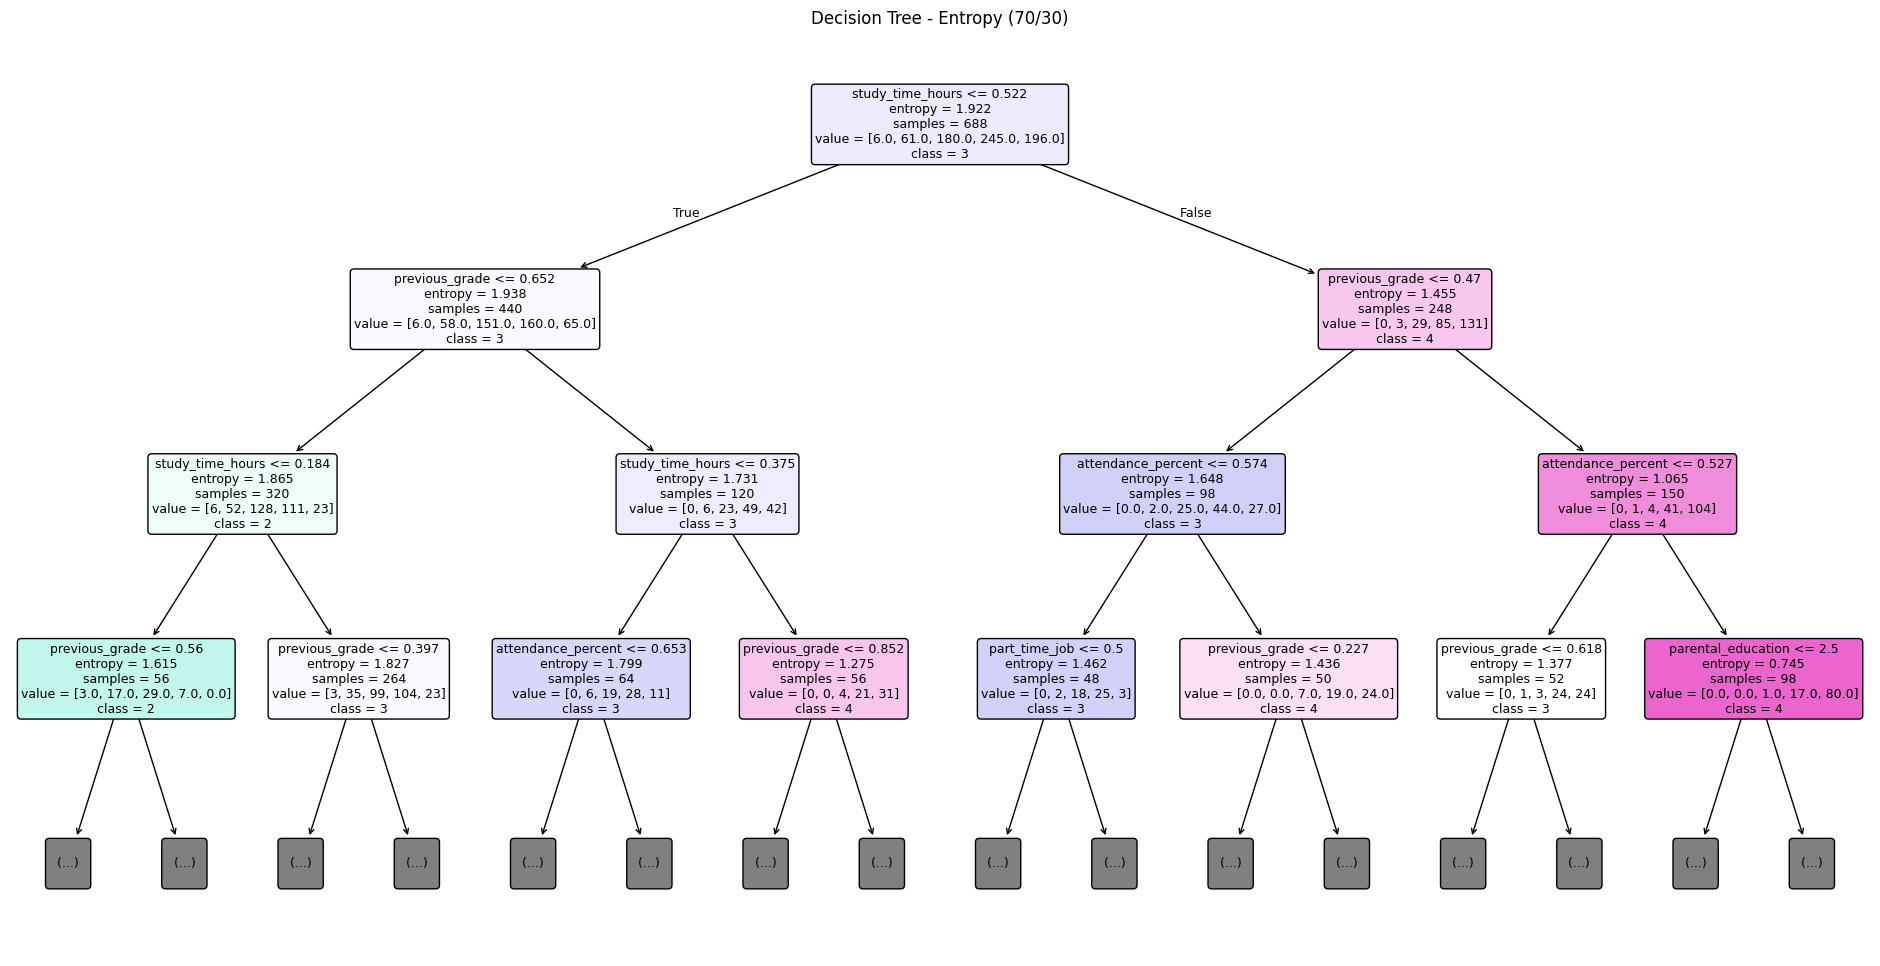

In [23]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(24, 12))

plot_tree(
    dt_entropy_70,
    feature_names=X.columns,
    class_names=[str(c) for c in dt_entropy_70.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree - Entropy (70/30)")
plt.show()

**Description:**

The Decision Tree visualization shows the main decision rules used by the Entropy-based classifier. Each internal node represents a decision based on a feature, while the branches represent the possible outcomes. The leaf nodes show the predicted class. The visualization helps illustrate how the model makes classification decisions.

#### 6.2 Clustering – Evaluation and Comparison

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

df = pd.read_csv("Preprocessed_dataset.csv")
label_col = "final_grade"
features = df.drop(label_col, axis=1)

scaled_features = StandardScaler().fit_transform(features)
data_scaled = pd.DataFrame(scaled_features, columns=features.columns)
print(data_scaled.head())

     gender  study_time_hours  attendance_percent  sleep_hours  \
0  1.026781          0.304615            1.409536    -0.257959   
1 -0.973917          1.886541            1.630906    -0.928807   
2  1.026781          0.923629            0.003836     0.916024   
3  1.026781         -0.658297           -0.859508     0.999880   
4  1.026781         -0.933415            0.479782    -1.851223   

   parental_education  internet_access  extracurricular_activities  \
0            0.192338         0.412354                    0.862949   
1           -0.914447         0.412354                    0.862949   
2            0.192338         0.412354                   -1.158817   
3           -0.914447         0.412354                    0.862949   
4            0.192338         0.412354                   -1.158817   

   part_time_job  previous_grade  final_exam_score  
0      -0.681385        0.563863          1.607952  
1       1.467599        0.451798          1.607952  
2       1.467599       

Elbow at k = 5


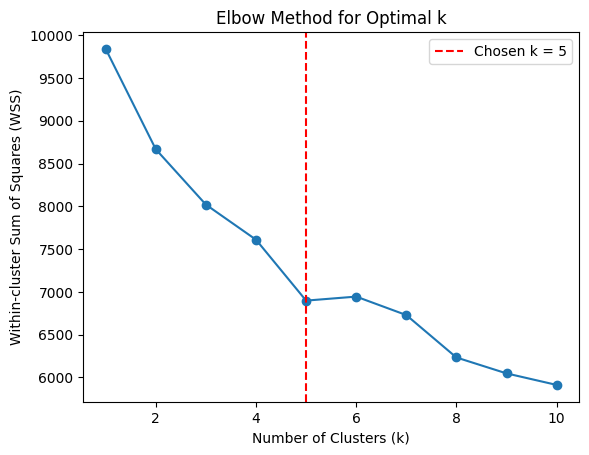

In [ ]:
%pip install Kneed
from kneed import KneeLocator

wss_values = []
k_values = range(1, 11)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42).fit(data_scaled)
    wss_values.append(km.inertia_)

knee = KneeLocator(list(k_values), wss_values, curve="convex", direction="decreasing")
print("Elbow at k =", knee.elbow)

plt.plot(k_values, wss_values, marker="o")
if knee.elbow is not None:
    plt.axvline(x=knee.elbow, linestyle="--", color="red", label=f"Chosen k = {knee.elbow}")
    plt.legend()
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-cluster Sum of Squares (WSS)")
plt.title("Elbow Method for Optimal k")
plt.show()

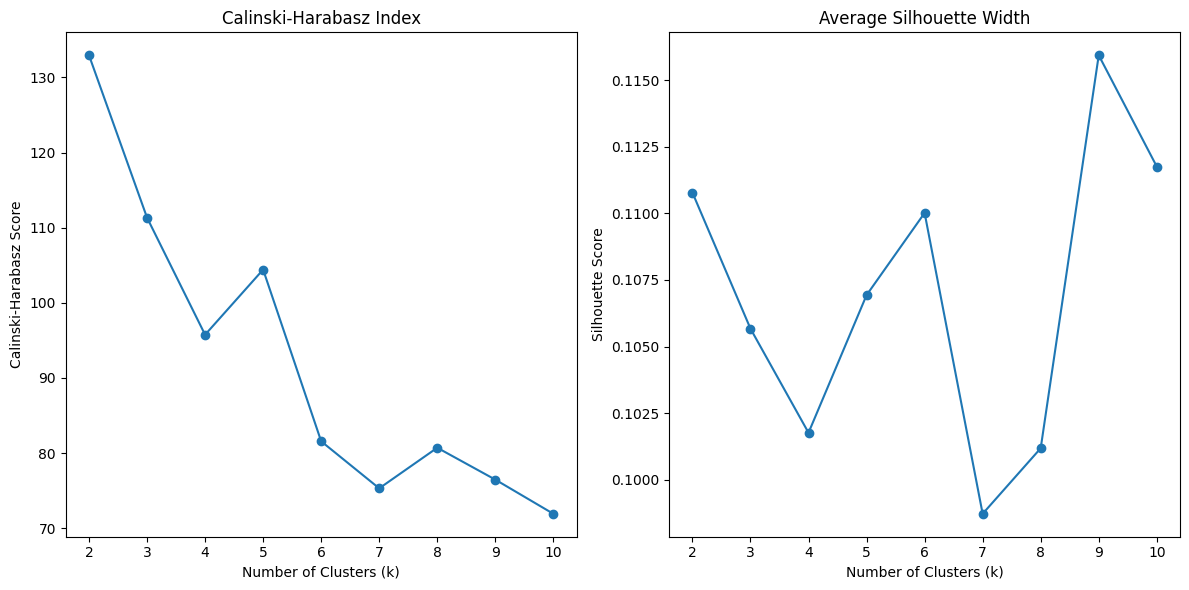

Best K by Silhouette: 9
Best K by Calinski-Harabasz: 2


In [ ]:
k_range = range(2, 11)
ch_scores, silhouette_scores = [], []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42).fit(data_scaled)
    ch_scores.append(calinski_harabasz_score(data_scaled, km.labels_))
    silhouette_scores.append(silhouette_score(data_scaled, km.labels_))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(k_range, ch_scores, marker="o")
plt.title("Calinski-Harabasz Index")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Calinski-Harabasz Score")
plt.subplot(1, 2, 2)
plt.plot(k_range, silhouette_scores, marker="o")
plt.title("Average Silhouette Width")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

best_sil = list(k_range)[silhouette_scores.index(max(silhouette_scores))]
best_ch = list(k_range)[ch_scores.index(max(ch_scores))]
print("Best K by Silhouette:", best_sil)
print("Best K by Calinski-Harabasz:", best_ch)

### Optimal K Choice & Justification
We tested K = 2 to 10 and selected K = 2, 3 and 4. K = 2 has the highest Calinski-Harabasz index (133.0) and a Silhouette of 0.111. The WSS decreases gradually without a sharp elbow, so we kept small K values for easier interpretation. All Silhouette values are low (about 0.10 to 0.12), which means the clusters overlap and the structure in the data is weak.

In [ ]:
ks = [2, 3, 4]
models = {}
for k in ks:
    models[k] = KMeans(n_clusters=k, random_state=42).fit(data_scaled)
    print(f"K={k} | Silhouette = {silhouette_score(data_scaled, models[k].labels_):.4f} | WSS = {models[k].inertia_:.2f}")

K=2 | Silhouette = 0.1108 | WSS = 8666.59
K=3 | Silhouette = 0.1057 | WSS = 8019.57
K=4 | Silhouette = 0.1018 | WSS = 7609.40


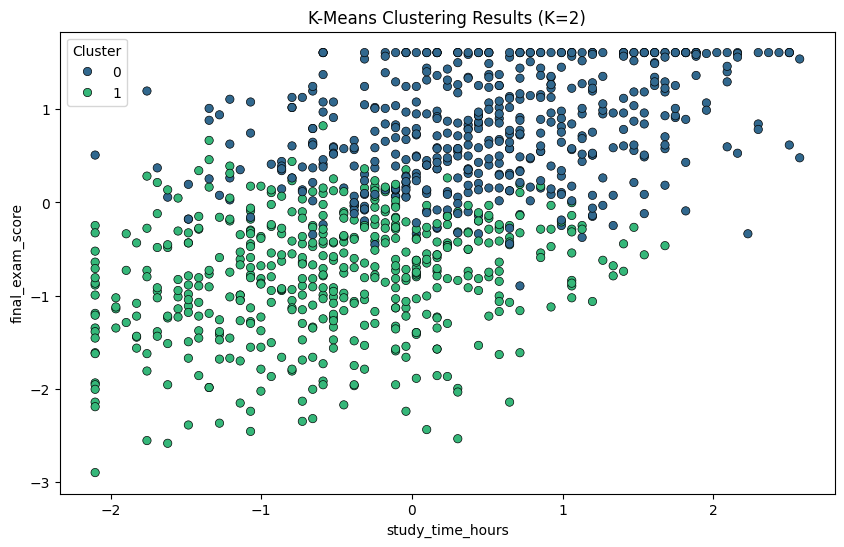

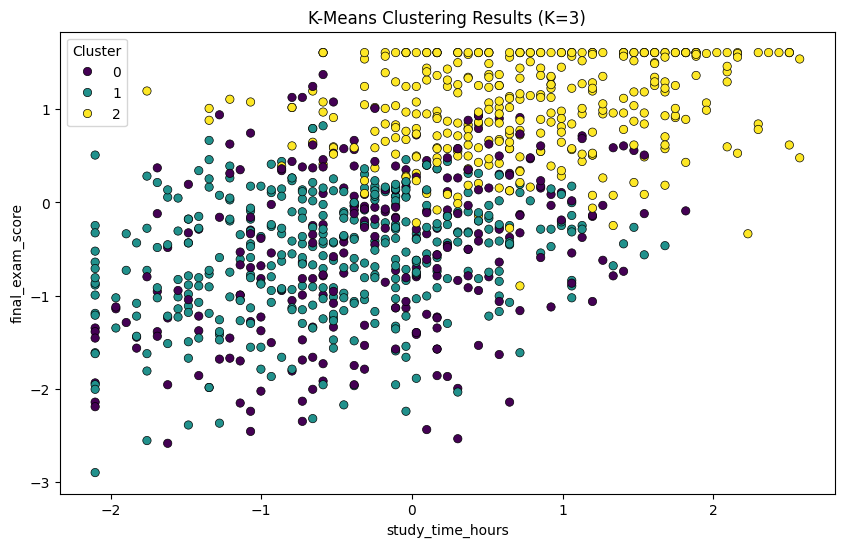

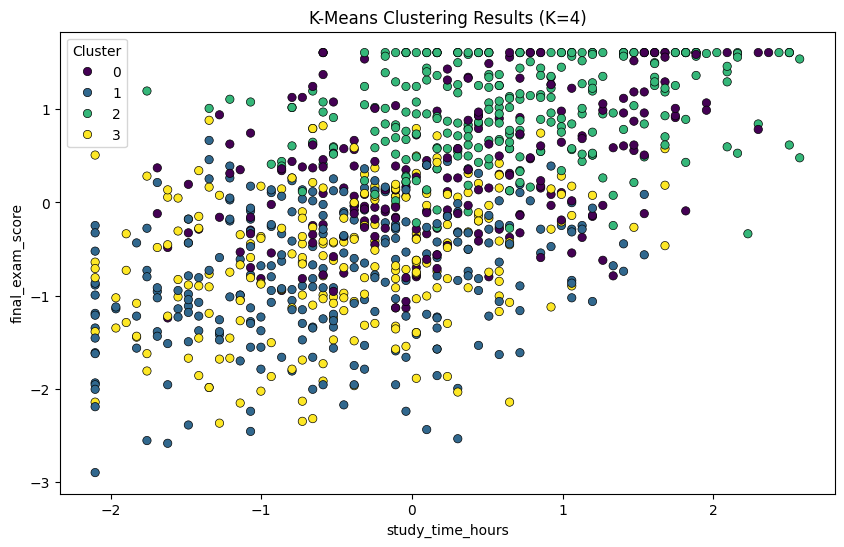

In [ ]:
for k in ks:
    plot_df = data_scaled.copy()
    plot_df["Cluster"] = models[k].labels_
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x="study_time_hours", y="final_exam_score", hue="Cluster",
                    data=plot_df, palette="viridis", edgecolor="k")
    plt.title(f"K-Means Clustering Results (K={k})")
    plt.show()

In [ ]:
summary = pd.DataFrame({
    f"K={k}": {
        "Average Silhouette width": silhouette_score(data_scaled, models[k].labels_),
        "Total within-cluster SS": models[k].inertia_
    } for k in ks
})
print(summary)

                                  K=2          K=3          K=4
Average Silhouette width     0.110783     0.105672     0.101762
Total within-cluster SS   8666.586183  8019.571831  7609.404585


- K=2: Silhouette = 0.111, WSS = 8666.6. The clusters overlap but this K has the best Silhouette and Calinski-Harabasz among the three.
- K=3: Silhouette = 0.106, WSS = 8019.6. WSS drops but the Silhouette is lower, so separation is slightly worse.
- K=4: Silhouette = 0.102, WSS = 7609.4. WSS drops more but the Silhouette is the lowest, so the clusters overlap more.

Best K (majority rule): K = 2, supported by the highest Calinski-Harabasz and the highest Silhouette among the three chosen values.

## [7]  Findings and Discussion:

## [8]  References: